# Feature extraction:



In [4]:
import numpy as np
import matplotlib.pyplot as plt

from Bio.SeqUtils.ProtParam import ProteinAnalysis
from Bio.SeqUtils import ProtParamData 


In [2]:
fasta=open('/home/um40/LB2_project_Group_1/von_Heijne_method/merged.fasta','r')

In [5]:
from aaindex_parse import parse_aaindex_file

In [6]:
with open('/home/um40/LB2_project_Group_1/Feature_Selection/AAindex_scales.txt','r') as f:
    dict_f={}
    for line in f:
        line=line.strip().split()
        dict_f[line[1]]=parse_aaindex_file("/home/um40/LB2_project_Group_1/Feature_Selection/aaindex1",line[0])


In [ ]:
#Amino acid scale: Transmembrane tendency ProtScale

dict_f['tt']={
    'Ala':  0.380,

'Arg': -2.570  ,

'Asn': -1.620  ,

'Asp': -3.270  ,

'Cys': -0.300  ,

'Gln': -1.840  ,

'Glu': -2.900  ,

'Gly': -0.190  ,

'His': -1.440  ,

'Ile':  1.970  ,

'Leu':  1.820  ,

'Lys': -3.460  ,

'Met':  1.400  ,

'Phe':  1.980  ,

'Pro': -1.440  ,

'Ser': -0.530  ,

'Thr': -0.320  ,

'Trp':  1.530  ,

'Tyr':  0.490  ,

'Val':  1.460 ,

}


In [8]:
dict_f

{'h': {'A': 1.8,
  'R': -4.5,
  'N': -3.5,
  'D': -3.5,
  'C': 2.5,
  'Q': -3.5,
  'E': -3.5,
  'G': -0.4,
  'H': -3.2,
  'I': 4.5,
  'L': 3.8,
  'K': -3.9,
  'M': 1.9,
  'F': 2.8,
  'P': -1.6,
  'S': -0.8,
  'T': -0.7,
  'W': -0.9,
  'Y': -1.3,
  'V': 4.2},
 'p': {'A': 0.0,
  'R': 1.0,
  'N': 0.0,
  'D': 0.0,
  'C': 0.0,
  'Q': 0.0,
  'E': 0.0,
  'G': 0.0,
  'H': 1.0,
  'I': 0.0,
  'L': 0.0,
  'K': 1.0,
  'M': 0.0,
  'F': 0.0,
  'P': 0.0,
  'S': 0.0,
  'T': 0.0,
  'W': 0.0,
  'Y': 0.0,
  'V': 0.0},
 'n': {'A': 0.0,
  'R': 0.0,
  'N': 0.0,
  'D': 1.0,
  'C': 0.0,
  'Q': 0.0,
  'E': 1.0,
  'G': 0.0,
  'H': 0.0,
  'I': 0.0,
  'L': 0.0,
  'K': 0.0,
  'M': 0.0,
  'F': 0.0,
  'P': 0.0,
  'S': 0.0,
  'T': 0.0,
  'W': 0.0,
  'Y': 0.0,
  'V': 0.0},
 'nf': {'A': 1.42,
  'R': 0.98,
  'N': 0.67,
  'D': 1.01,
  'C': 0.7,
  'Q': 1.11,
  'E': 1.51,
  'G': 0.57,
  'H': 1.0,
  'I': 1.08,
  'L': 1.21,
  'K': 1.16,
  'M': 1.45,
  'F': 1.13,
  'P': 0.57,
  'S': 0.77,
  'T': 0.83,
  'W': 1.08,
  'Y': 0.69

- pos value --> more hydrophobic
- neg value --> less hydrophobic

Since a scale is just a dictionary, nothing prevents us from writing our own,
or from copying any of the ~500 scales collected in the
[AAindex database](https://www.genome.jp/aaindex/). Everything below works with any scale.

---
# Part A — The sliding window, step by step

We start with a short sequence, so that we can follow every number.

In [ ]:
sequence = "MKTLLILAVVAAALA"     # a short, made-up sequence (hydrophobic in the middle)
L = len(sequence)
print("Length:", L)

Length: 15


### A.1 Step 1: one value per residue

Look up each residue in the scale. This is already a numerical encoding of the sequence
(one number per position), but it is very noisy: single residues fluctuate a lot.

In [ ]:
values = []
for aa in sequence:
    values.append(kd[aa])

# Results for w=1 => hydrophobicity value of each aa in the seq (no context, individual value)
for i in range(L):
    print(f"position {i+1:2d}   {sequence[i]}   {values[i]:+5.1f}")

position  1   M    +1.9
position  2   K    -3.9
position  3   T    -0.7
position  4   L    +3.8
position  5   L    +3.8
position  6   I    +4.5
position  7   L    +3.8
position  8   A    +1.8
position  9   V    +4.2
position 10   V    +4.2
position 11   A    +1.8
position 12   A    +1.8
position 13   A    +1.8
position 14   L    +3.8
position 15   A    +1.8


### A.2 Step 2: average over a window

With a window of size `w` (odd), the value of residue `i` is the **mean of the scale values of the
`w` residues centred on `i`**: `d = w // 2` residues on the left, the residue itself, `d` on the right.

```
w = 5, d = 2

sequence:   M  K  T  L  L  I  L  A  ...
                  [-----------]          window centred on position 5 (L)
                  T  L  L  I  L   -> mean of 5 values -> profile value of position 5
```

A window can be placed only where it fits entirely inside the sequence.
The first full window is centred on residue `d`, the last one on residue `L - 1 - d`
(0-based). So we get **`L - w + 1` values**, not `L`.

In [ ]:
def window_profile(values, w):
    # mean of w consecutive values; returns L - w + 1 numbers
    profile = []
    for start in range(len(values) - w + 1):
        window = values[start : start + w]
        profile.append(sum(window) / w)
    return profile

w = 5
d = w // 2
my_profile = window_profile(values, w)

print("number of values:", len(my_profile), "   (L - w + 1 =", L - w + 1, ")")
for k, value in enumerate(my_profile):
    centre = k + d                     # 0-based index of the central residue
    print(f"window {k:2d}: residues {k+1:2d}-{k+w:2d}  centre = position {centre+1:2d} ({sequence[centre]})   {value:+.2f}")

number of values: 11    (L - w + 1 = 11 )
window  0: residues  1- 5  centre = position  3 (T)   +0.98
window  1: residues  2- 6  centre = position  4 (L)   +1.50
window  2: residues  3- 7  centre = position  5 (L)   +3.04
window  3: residues  4- 8  centre = position  6 (I)   +3.54
window  4: residues  5- 9  centre = position  7 (L)   +3.62
window  5: residues  6-10  centre = position  8 (A)   +3.70
window  6: residues  7-11  centre = position  9 (V)   +3.16
window  7: residues  8-12  centre = position 10 (V)   +2.76
window  8: residues  9-13  centre = position 11 (A)   +2.76
window  9: residues 10-14  centre = position 12 (A)   +2.68
window 10: residues 11-15  centre = position 13 (A)   +2.20


**Important:** the first value of the profile does **not** belong to residue 1, but to residue `d + 1`.
If you forget this shift, your profile is misaligned with the sequence by `d` positions.

### A.3 Step 3: the same thing with Biopython

`ProteinAnalysis.protein_scale(scale, window)` does exactly what we did above.
Let us check that the numbers are identical.

In [ ]:
bio_profile = ProteinAnalysis(sequence).protein_scale(kd, w) # scale = kd, window_size = w

print("Biopython:", np.round(bio_profile, 2))
print("by hand  :", np.round(my_profile, 2))
print("identical?", np.allclose(bio_profile, my_profile))

Biopython: [0.98 1.5  3.04 3.54 3.62 3.7  3.16 2.76 2.76 2.68 2.2 ]
by hand  : [0.98 1.5  3.04 3.54 3.62 3.7  3.16 2.76 2.76 2.68 2.2 ]
identical? True


### A.4 A hidden parameter: `edge`

`protein_scale` has a third argument, `edge` (default `1.0`). By default all residues in the window
count the same. With `edge < 1` the residues at the borders of the window weigh **less** than the central one;
the weights grow linearly from `edge` (borders) to `1` (centre). Example for `w = 5`, `edge = 0.4`:

```
weights:  0.4  0.7  1.0  0.7  0.4
```

and the profile value is a **weighted mean**: `sum(weight * value) / sum(weights)`.
Let us write it by hand too.

In [ ]:
def window_weights(w, edge):
    # linear weights: edge at the borders, 1 at the centre (symmetric)
    d = w // 2
    step = (1.0 - edge) / d
    left = [edge + step * j for j in range(d)]        # e.g. [0.4, 0.7]
    return left + [1.0] + left[::-1]                   # e.g. [0.4, 0.7, 1.0, 0.7, 0.4]

def weighted_window_profile(values, w, edge):
    weights = window_weights(w, edge)
    profile = []
    for start in range(len(values) - w + 1):
        window = values[start : start + w]
        score = 0.0
        for x, wt in zip(window, weights):
            score += x * wt
        profile.append(score / sum(weights))
    return profile

print("weights:", window_weights(5, 0.4))
mine = weighted_window_profile(values, 5, 0.4)
bio  = ProteinAnalysis(sequence).protein_scale(kd, 5, edge=0.4)
print("identical?", np.allclose(mine, bio))

weights: [0.4, 0.7, 1.0, 0.7, 0.4]
identical? True


### A.5 The sequence ends: getting `L` values instead of `L - w + 1`

We usually want **one value per residue** (e.g. to put the profile next to other per-residue features).
The first and last `d` residues have no complete window, so we must decide what to do with them.
Three common choices:

1. **Leave them empty** (no value, `NaN`).
2. **Zero padding**: pretend there are `d` extra residues with value 0 before and after the sequence.
3. **Shrinking window**: near the ends, average only over the residues that actually exist.

Each choice is a *design decision* of the feature extraction, and it changes the numbers at the ends.
Let us implement all three with the same simple loop.

In [ ]:
def full_length_profile(values, w, mode):
    L = len(values)
    d = w // 2
    profile = []
    for i in range(L):                         # one value for EVERY residue i
        window = []
        n_missing = 0
        for j in range(i - d, i + d + 1):      # positions covered by the window centred on i
            if 0 <= j < L:
                window.append(values[j])
            else:
                n_missing += 1                 # this position is outside the sequence
        if mode == "empty":
            profile.append(np.nan if n_missing > 0 else sum(window) / w)
        elif mode == "zero":
            profile.append(sum(window) / w)    # missing positions count as 0, but we still divide by w
        elif mode == "shrink":
            profile.append(sum(window) / len(window))   # divide only by the residues that exist
    return profile

print("pos aa    empty    zero  shrink")
p_empty  = full_length_profile(values, 5, "empty")
p_zero   = full_length_profile(values, 5, "zero")
p_shrink = full_length_profile(values, 5, "shrink")
for i in range(L):
    print(f"{i+1:3d}  {sequence[i]}   {p_empty[i]:+6.2f}  {p_zero[i]:+6.2f}  {p_shrink[i]:+6.2f}")

pos aa    empty    zero  shrink
  1  M     +nan   -0.54   -0.90
  2  K     +nan   +0.22   +0.27
  3  T    +0.98   +0.98   +0.98
  4  L    +1.50   +1.50   +1.50
  5  L    +3.04   +3.04   +3.04
  6  I    +3.54   +3.54   +3.54
  7  L    +3.62   +3.62   +3.62
  8  A    +3.70   +3.70   +3.70
  9  V    +3.16   +3.16   +3.16
 10  V    +2.76   +2.76   +2.76
 11  A    +2.76   +2.76   +2.76
 12  A    +2.68   +2.68   +2.68
 13  A    +2.20   +2.20   +2.20
 14  L     +nan   +1.84   +2.30
 15  A     +nan   +1.48   +2.47


OBSERVATION: in the zero column, the first/last values will be smaller than the ones in shrink column because the zeros that we consider bias the result.

In the middle of the sequence the three columns are identical; they differ only in the first and last `d` residues.
Zero padding pulls the ends towards 0 (here this makes the hydrophobic C-terminus look *less* hydrophobic),
the shrinking window keeps them on the same scale as the rest of the profile, but averages over fewer residues.

#### What about padding with `X`?

A trick you may find online is to add `d` copies of `X` at both ends and call `protein_scale`:
`X` is not in the scale, so the hope is that it behaves like zero padding. Let us check.

In [ ]:
padded = "X" * d + sequence + "X" * d
bio_padded = ProteinAnalysis(padded).protein_scale(kd, 5)

print("length:", len(bio_padded))
print("pos  zero-pad  X-pad (Biopython)")
for i in range(4):
    print(f"{i+1:3d}  {p_zero[i]:+8.2f}  {bio_padded[i]:+8.2f}")

length: 15
pos  zero-pad  X-pad (Biopython)
  1     -0.54     +0.38
  2     +0.22     -0.54
  3     +0.98     +0.98
  4     +1.50     +1.50


OBSERVATION: biopython with zero-padding leads to different result with respect our zero-padding. Why?

The length is right, but the values at the ends are **neither** zero padding **nor** the shrinking window.
The reason is in Biopython's code: it reads the window in **symmetric pairs in the window** (first and last residue,
second and second-to-last, ...) and, if one residue of a pair is not in the scale, it **skips the whole pair**.
So for residue 1, the window `X X M K T` loses `X`/`T` and `X`/`K`, and only `M` is left (divided by 5).

The same happens for a non-standard residue *inside* a sequence (e.g. `U`, selenocysteine, or `X`, unknown):
Biopython prints a warning and silently drops its partner residue too.

> **Lesson:** when a library makes a choice for you, check what it actually computes.
> Here, writing the loop ourselves makes the behaviour at the ends (and on unknown residues) explicit
> and under our control.

A simple, explicit way to handle unknown residues is to treat them like positions outside the sequence:
skip them and average over the residues that are known (the "shrink" idea).

In [ ]:
def hydrophobicity_profile(sequence, scale, w):
    # one value per residue; ends and unknown residues handled with the shrinking window
    L = len(sequence)
    d = w // 2
    profile = []
    for i in range(L):
        window = []
        for j in range(i - d, i + d + 1):
            if 0 <= j < L and sequence[j] in scale:     # inside the sequence AND a known residue
                window.append(scale[sequence[j]])
        profile.append(sum(window) / len(window) if window else np.nan)
    return np.array(profile)

test = "MAEUEITTFTALTEKF"         # contains U (selenocysteine)
print(np.round(hydrophobicity_profile(test, kd, 5), 2))

[ 0.07  0.07 -0.82 -0.18 -0.8  -0.1   0.48  1.04  0.5   1.4   1.4   0.14
 -0.5  -0.3  -1.32 -1.53]


---
# Part B — A real protein: Glycophorin A

Human **Glycophorin A** ([UniProt P02724](https://www.uniprot.org/uniprotkb/P02724/entry)) is a
single-pass membrane protein of red blood cells. Its UniProt annotation reports:

| region | residues |
|---|---|
| signal peptide | 1–19 |
| extracellular domain | 20–91 |
| **transmembrane helix** | **92–114** |
| cytoplasmic domain | 115–150 |

A transmembrane helix must cross the lipid bilayer, whose core is hydrophobic: about 20 consecutive,
mostly hydrophobic residues. Let us see whether the hydrophobicity profile finds it.

In [ ]:
gypa = ("MYGKIIFVLLLSEIVSISALSTTEVAMHTSTSSSVTKSYISSQTNDTHKRDTYAATPRAH"
        "EVSEISVRTVYPPEEETGERVQLAHHFSEPEITLIIFGVMAGVIGTILLISYGIRRLIKK"
        "SPSDVKPLPSPDTDVPLSSVEIENPETSDQ")

# UniProt annotation (1-based, inclusive)
signal_peptide = (1, 19)
tm_helix       = (92, 114)

print("length:", len(gypa))
print("signal peptide :", gypa[signal_peptide[0]-1 : signal_peptide[1]])
print("TM helix       :", gypa[tm_helix[0]-1 : tm_helix[1]])

length: 150
signal peptide : MYGKIIFVLLLSEIVSISA
TM helix       : ITLIIFGVMAGVIGTILLISYGI


### B.1 The profile with a window of 19

Kyte and Doolittle suggested a window of **19** residues to look for transmembrane segments,
and a threshold of about **1.6**: windows above it are good candidates.

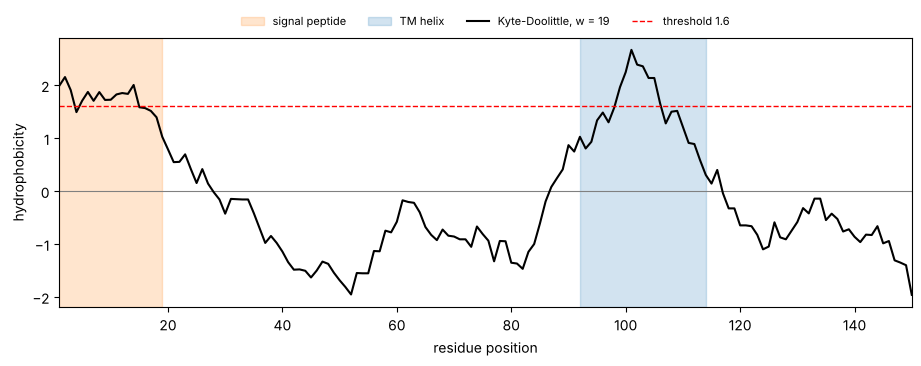

In [ ]:
positions = np.arange(1, len(gypa) + 1)        # 1-based residue numbers, for the plots

def shade_annotation(ax):
    ax.axvspan(signal_peptide[0], signal_peptide[1], color="tab:orange", alpha=0.2, label="signal peptide")
    ax.axvspan(tm_helix[0], tm_helix[1], color="tab:blue", alpha=0.2, label="TM helix")
    ax.axhline(0, color="grey", lw=0.8)

profile19 = hydrophobicity_profile(gypa, kd, 19)

fig, ax = plt.subplots(figsize=(11, 3.5))
shade_annotation(ax)
ax.plot(positions, profile19, color="black", lw=1.5, label="Kyte-Doolittle, w = 19")
ax.axhline(1.6, color="red", ls="--", lw=1, label="threshold 1.6")
ax.set_xlabel("residue position")
ax.set_ylabel("hydrophobicity")
ax.set_xlim(1, len(gypa))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, fontsize=8, frameon=False)
plt.show()

Two hydrophobic regions stand out: the **TM helix** (as expected) and the **signal peptide**.
Signal peptides have a hydrophobic core (the *h-region*) that is recognised by the translocation machinery.

### B.2 Which residues are above the threshold?

From a profile we can extract **segments**: runs of consecutive residues above the threshold.

In [ ]:
def segments_above(profile, threshold):
    # returns a list of (start, end) segments, 1-based and inclusive
    segments = []
    start = None
    for i, value in enumerate(profile):
        if value >= threshold and start is None:
            start = i                                   # a segment begins
        if value < threshold and start is not None:
            segments.append((start + 1, i))             # the segment ended at the previous residue
            start = None
    if start is not None:                               # a segment still open at the end
        segments.append((start + 1, len(profile)))
    return segments

for s, e in segments_above(profile19, 1.6):
    print(f"residues {s:3d}-{e:3d}   ({e - s + 1} residues)   {gypa[s-1:e]}")

residues   1-  3   (3 residues)   MYG
residues   5- 14   (10 residues)   IIFVLLLSEI
residues  99-106   (8 residues)   VMAGVIGT


Remember what each value means: residue `i` is above threshold if the **19-residue window centred on `i`**
is hydrophobic on average. So the segments we find mark the *centres* of hydrophobic windows:
they fall inside the annotated regions, but they are shorter than them: a window centred near the border
of the TM helix also contains hydrophilic residues of the flanking loops, which lower its average.

At the N-terminus, residues 1–3 are above threshold too. This is an effect of our edge strategy (A.5):
near the end the window shrinks, and it only covers the hydrophobic beginning of the signal peptide
(see exercise 3).

Notice also that the profile **cannot tell a signal peptide from a TM helix**: both are hydrophobic stretches.
This is a classic problem (TM predictors often mistake signal peptides for TM helices, and vice versa),
and it is a good example of why one feature is rarely enough: we will need other features
(position in the sequence, charges, composition, ...) to separate them.

### B.3 The effect of the window size

The window size is a **parameter of the feature extraction**. Let us compare three values.

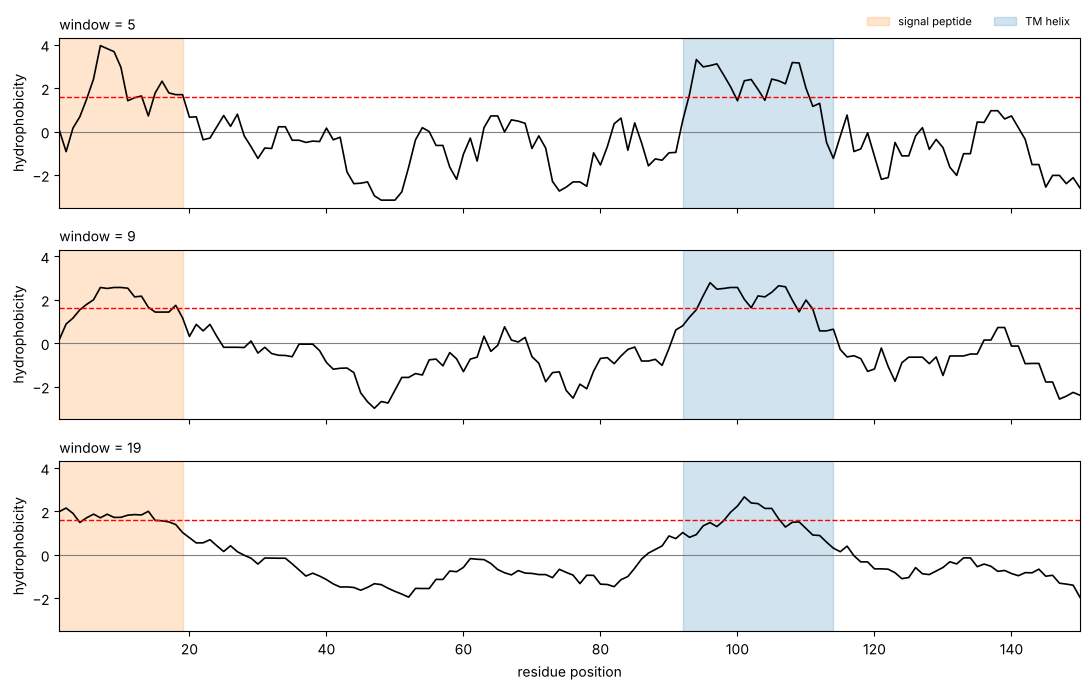

w =  5: min -3.16  max +3.96  segments above 1.6: [(6, 10), (13, 13), (15, 19), (93, 99), (101, 103), (105, 110)]
w =  9: min -3.00  max +2.79  segments above 1.6: [(5, 14), (18, 18), (95, 108), (110, 110)]
w = 19: min -1.96  max +2.67  segments above 1.6: [(1, 3), (5, 14), (99, 106)]


In [ ]:
window_sizes = [5, 9, 19]

fig, axes = plt.subplots(len(window_sizes), 1, figsize=(11, 7), sharex=True, sharey=True)
for ax, w in zip(axes, window_sizes):
    shade_annotation(ax)
    ax.plot(positions, hydrophobicity_profile(gypa, kd, w), color="black", lw=1.2)
    ax.axhline(1.6, color="red", ls="--", lw=1)
    ax.set_ylabel("hydrophobicity")
    ax.set_title(f"window = {w}", fontsize=10, loc="left")
axes[-1].set_xlabel("residue position")
axes[-1].set_xlim(1, len(gypa))
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

for w in window_sizes:
    p = hydrophobicity_profile(gypa, kd, w)
    print(f"w = {w:2d}: min {np.nanmin(p):+.2f}  max {np.nanmax(p):+.2f}  "
          f"segments above 1.6: {segments_above(p, 1.6)}")

* **Small window (5):** the profile follows single residues and is very jagged. The TM helix is broken into
  several short pieces, because one or two polar residues (e.g. the `T` and `S` inside the helix) are enough to
  push a 5-residue average below the threshold. Outside the membrane regions there are many local peaks:
  with a slightly lower threshold they would become false alarms.
* **Large window (19):** the profile is smooth; only regions that are hydrophobic over ~20 residues stand out.
  This matches the length of a TM helix, which is why Kyte and Doolittle proposed 19 for this task.
* The larger the window, the more the extreme values are flattened: the maximum goes from +3.96 (w = 5) to +2.67 (w = 19).

There is no universally "right" window: it depends on the size of the structural feature you want to capture
(a TM helix ≈ 20 residues, an amphipathic helix turn ≈ 3–4, a short motif ≈ 5–7).
In a machine-learning setting, the window size is a parameter you can choose, ideally with a validation procedure.

### B.4 From profile to features

The profile is a **per-residue feature**: a vector of length `L`, one value per position.
This is what you need when the prediction is made per residue (e.g. "is this residue in a TM helix?").
For a per-protein prediction (e.g. "does this protein have a signal peptide?") the vector must be
reduced to a fixed length: for example the maximum hydrophobicity, or the mean over the first 30 residues.

In [ ]:
features = {
    "max hydrophobicity (w=19)":          np.nanmax(profile19),
    "mean hydrophobicity, whole protein": np.nanmean(hydrophobicity_profile(gypa, kd, 1)),
    "mean hydrophobicity, first 30 res.": np.nanmean(hydrophobicity_profile(gypa[:30], kd, 1)),
}
for name, value in features.items():
    print(f"{name:38s} {value:+.2f}")

max hydrophobicity (w=19)              +2.67
mean hydrophobicity, whole protein     -0.08
mean hydrophobicity, first 30 res.     +1.14


---
## Exercises

1. **Another scale.** `ProtParamData` contains other scales, for example Hopp–Woods hydrophilicity
   (`ProtParamData.hw`) and Emini surface accessibility (`ProtParamData.em`); print `dir(ProtParamData)` to see them all.
   Recompute the Glycophorin A profile with `ProtParamData.hw`. Hopp–Woods is a *hydrophilicity* scale:
   what do you expect to see in the TM region?
2. **Your own scale.** Take a scale from [AAindex](https://www.genome.jp/aaindex/), write it as a dictionary,
   and plot the profile. Nothing else in the code needs to change.
3. **Ends.** Plot the first 20 residues of Glycophorin A with the three edge strategies of A.5 (`empty`, `zero`, `shrink`)
   and `w = 19`. Which one would you use to describe a signal peptide, which sits exactly at the N-terminus?
4. **Threshold.** How many residues are above threshold if you use 1.0 or 2.0 instead of 1.6, with `w = 19`?
   And with `w = 9`?
5. **Another protein.** Download from UniProt a protein with several TM helices
   (e.g. bacteriorhodopsin, P02945) and count how many segments your profile finds.
   Compare with the UniProt annotation.

4PROJECT: after computed the hydrophobicity sequence (one value for each residue), we have to compute the avg and max value as the feature to be use with the model.